# TA-03: Data-Driven Monte Carlo Simulation
## Estimasi Risiko Klaim Asuransi Kesehatan
**Nama:** Irfan Dwi Darmawan  
**NIM:** 301240034  
**Kelas:** 5 A  
**Mata Praktikum:** Pemodelan dan Simulasi

## Studi Kasus
Digit terakhir NIM adalah **4**, sehingga topik yang dikerjakan adalah **Estimasi Risiko Klaim Asuransi** dengan dataset *Medical Cost Personal Datasets* (Kaggle) dan fitur `charges`.

**Pertanyaan bisnis:** Jika ada **100 pasien baru**, berapa **probabilitas total klaim melebihi anggaran** perusahaan?

**Anggaran (asumsi):** US$ 1.400.000 untuk 100 pasien, yaitu sekitar US$ 14.000 per pasien. Angka ini sedikit di atas rata-rata historis sehingga risiko kelebihan klaim terlihat jelas; nilainya dapat diubah di sel parameter.

**Alur:** data Kaggle → pembersihan → ekstraksi parameter (μ, σ) → simulasi Monte Carlo (5.000+ skenario) → analisis risiko.

## Langkah 0. Import Library dan Seed NIM

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NIM = 301240034          # seed memakai NIM agar hasil dapat direproduksi
np.random.seed(NIM)
print("Seed diatur menggunakan NIM:", NIM)

Seed diatur menggunakan NIM: 301240034


## Langkah 1. Eksplorasi Data Kaggle
### 1.1 Memuat Data
Dataset: https://www.kaggle.com/datasets/mirichoi0218/insurance (berkas `insurance.csv`). Jika berkas belum diunggah ke Colab, data diambil dari salinan publik yang identik.

In [2]:
try:
    df = pd.read_csv("insurance.csv")
except FileNotFoundError:
    # salinan publik berkas yang sama (dipakai bila insurance.csv belum diunggah)
    df = pd.read_csv("https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv")

print("Bentuk data:", df.shape)
df.head()

Bentuk data: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### 1.2 Data Cleaning

In [3]:
print("Nilai kosong per kolom:")
print(df.isna().sum())
print("\nBaris duplikat:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)
print("Bentuk data setelah menghapus duplikat:", df.shape)

# Pemeriksaan outlier pada charges dengan aturan IQR
q1, q3 = df["charges"].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
n_outlier = (df["charges"] > batas_atas).sum()
print(f"\nBatas atas IQR: {batas_atas:,.0f} | jumlah klaim di atas batas: {n_outlier}")

Nilai kosong per kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Baris duplikat: 1
Bentuk data setelah menghapus duplikat: (1337, 7)

Batas atas IQR: 34,525 | jumlah klaim di atas batas: 139


**Keputusan terhadap outlier:** klaim yang sangat besar **tidak dihapus**. Nilai-nilai tersebut adalah klaim nyata (umumnya milik perokok dengan BMI tinggi), dan justru klaim besar inilah yang menentukan risiko kelebihan anggaran. Menghapusnya akan membuat risiko tampak lebih kecil dari kenyataan. Data tidak memiliki nilai kosong, dan satu baris duplikat dihapus.

### 1.3 Ekstraksi Parameter (Mean dan Standar Deviasi)

In [4]:
charges = df["charges"].to_numpy()

mu = charges.mean()
sigma = charges.std(ddof=1)

print(f"Jumlah data   : {len(charges)}")
print(f"Mean (μ)      : {mu:,.2f}")
print(f"Std Dev (σ)   : {sigma:,.2f}")
print(f"Median        : {np.median(charges):,.2f}")
print(f"Min / Max     : {charges.min():,.2f} / {charges.max():,.2f}")
print(f"Skewness      : {pd.Series(charges).skew():.3f}")

# peluang nilai negatif jika charges dianggap berdistribusi Normal(μ, σ)
p_negatif = 0.5 * math.erfc((mu / sigma) / math.sqrt(2))
print(f"P(nilai < 0) pada Normal(μ, σ): {p_negatif:.1%}")

print("\nStatistik per kelompok perokok:")
print(df.groupby("smoker")["charges"].agg(["count", "mean", "std"]).round(1))

Jumlah data   : 1337
Mean (μ)      : 13,279.12
Std Dev (σ)   : 12,110.36
Median        : 9,386.16
Min / Max     : 1,121.87 / 63,770.43
Skewness      : 1.515
P(nilai < 0) pada Normal(μ, σ): 13.6%

Statistik per kelompok perokok:
        count     mean      std
smoker                         
no       1063   8440.7   5993.0
yes       274  32050.2  11541.5


### 1.4 Histogram Data Asli

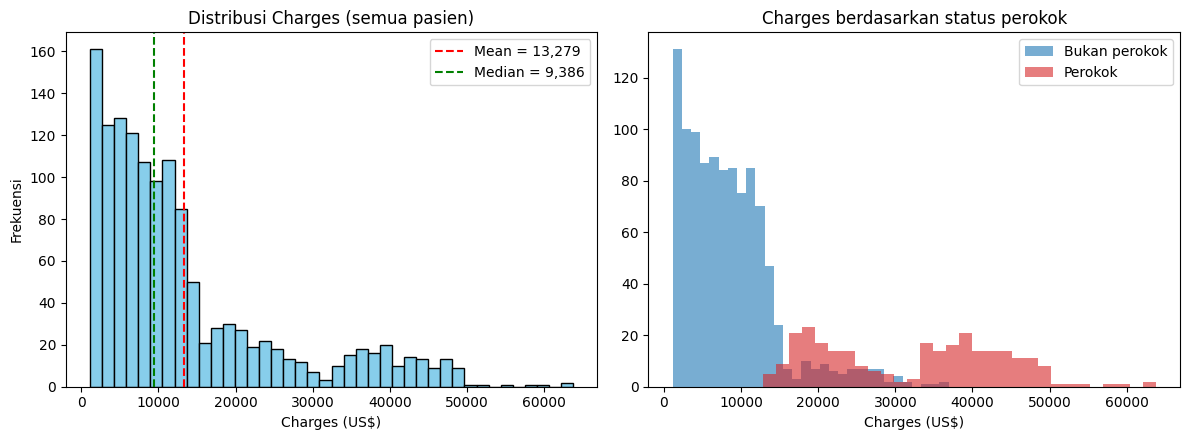

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(charges, bins=40, color="skyblue", edgecolor="black")
axes[0].axvline(mu, color="red", ls="--", label=f"Mean = {mu:,.0f}")
axes[0].axvline(np.median(charges), color="green", ls="--", label=f"Median = {np.median(charges):,.0f}")
axes[0].set_title("Distribusi Charges (semua pasien)")
axes[0].set_xlabel("Charges (US$)"); axes[0].set_ylabel("Frekuensi"); axes[0].legend()

for status, warna in [("no", "tab:blue"), ("yes", "tab:red")]:
    axes[1].hist(df.loc[df["smoker"] == status, "charges"], bins=30, alpha=0.6, color=warna,
                 label="Perokok" if status == "yes" else "Bukan perokok")
axes[1].set_title("Charges berdasarkan status perokok")
axes[1].set_xlabel("Charges (US$)"); axes[1].legend()
plt.tight_layout()
plt.savefig("histogram_data_asli.png", dpi=130)
plt.show()

**Pengamatan:** distribusi `charges` **condong ke kanan** (skewness sekitar 1,5; mean lebih besar dari median) dan tidak berbentuk lonceng. Penyebabnya adalah dua kelompok yang berbeda: pasien perokok memiliki klaim jauh lebih tinggi daripada yang bukan perokok. Distribusi Normal(μ, σ) tidak cocok untuk satu klaim, sehingga selain model Normal (sesuai ketentuan tugas) dibuat juga model **bootstrap** yang mengambil sampel langsung dari data.

## Langkah 2. Membangun Simulasi Monte Carlo

In [6]:
N_PASIEN = 100          # jumlah pasien baru
N_SIM = 10_000          # jumlah skenario (minimal 5.000)
ANGGARAN = 1_400_000    # anggaran total klaim untuk 100 pasien (US$)

print(f"Ekspektasi total klaim (N x μ) : {N_PASIEN * mu:,.0f}")
print(f"Anggaran                      : {ANGGARAN:,.0f}  ({ANGGARAN / (N_PASIEN * mu) - 1:+.1%} dari ekspektasi)")

Ekspektasi total klaim (N x μ) : 1,327,912
Anggaran                      : 1,400,000  (+5.4% dari ekspektasi)


### Model A: distribusi Normal(μ, σ)
Setiap skenario menarik 100 klaim dari Normal(μ, σ) lalu menjumlahkannya.

In [7]:
np.random.seed(NIM)
klaim_A = np.random.normal(mu, sigma, size=(N_SIM, N_PASIEN))
total_A = klaim_A.sum(axis=1)          # total klaim tiap skenario
print("Contoh 5 total klaim pertama (Model A):", np.round(total_A[:5], 0))

Contoh 5 total klaim pertama (Model A): [1497364. 1147922. 1372957. 1558897. 1435735.]


### Model B: bootstrap dari data historis
Setiap skenario menarik 100 klaim (dengan pengembalian) dari 1.337 klaim nyata, sehingga bentuk distribusi asli yang condong ke kanan ikut terbawa.

In [8]:
np.random.seed(NIM)
klaim_B = np.random.choice(charges, size=(N_SIM, N_PASIEN), replace=True)
total_B = klaim_B.sum(axis=1)
print("Contoh 5 total klaim pertama (Model B):", np.round(total_B[:5], 0))

Contoh 5 total klaim pertama (Model B): [1149960. 1350134. 1266542. 1237516. 1375372.]


## Langkah 3. Analisis Risiko
### 3.1 Probabilitas Total Klaim Melebihi Anggaran
P(Event) = jumlah skenario yang memenuhi kondisi / total skenario.

In [9]:
def ringkas(total, nama):
    return {
        "Model": nama,
        "Rata-rata total": total.mean(),
        "Std total": total.std(),
        "P(total > anggaran)": (total > ANGGARAN).mean(),
        "Persentil 95": np.percentile(total, 95),
        "Persentil 99": np.percentile(total, 99),
    }

hasil = pd.DataFrame([ringkas(total_A, "A: Normal"), ringkas(total_B, "B: Bootstrap")]).set_index("Model")
pd.options.display.float_format = "{:,.4f}".format
print(hasil.round(4).to_string())

# validasi dengan Central Limit Theorem: jumlah 100 klaim ~ Normal(N·μ, σ·√N)
z = (ANGGARAN - N_PASIEN * mu) / (sigma * math.sqrt(N_PASIEN))
p_clt = 0.5 * math.erfc(z / math.sqrt(2))
print(f"\nP(total > anggaran) secara teoritis (CLT): {p_clt:.4f}")

              Rata-rata total    Std total  P(total > anggaran)   Persentil 95   Persentil 99
Model                                                                                        
A: Normal      1,328,378.2358 122,800.7331               0.2764 1,529,388.8333 1,617,929.5747
B: Bootstrap   1,328,269.4950 121,477.5764               0.2735 1,532,190.5904 1,627,224.9013

P(total > anggaran) secara teoritis (CLT): 0.2758


### 3.2 Visualisasi Hasil dengan Garis Batas (Threshold)

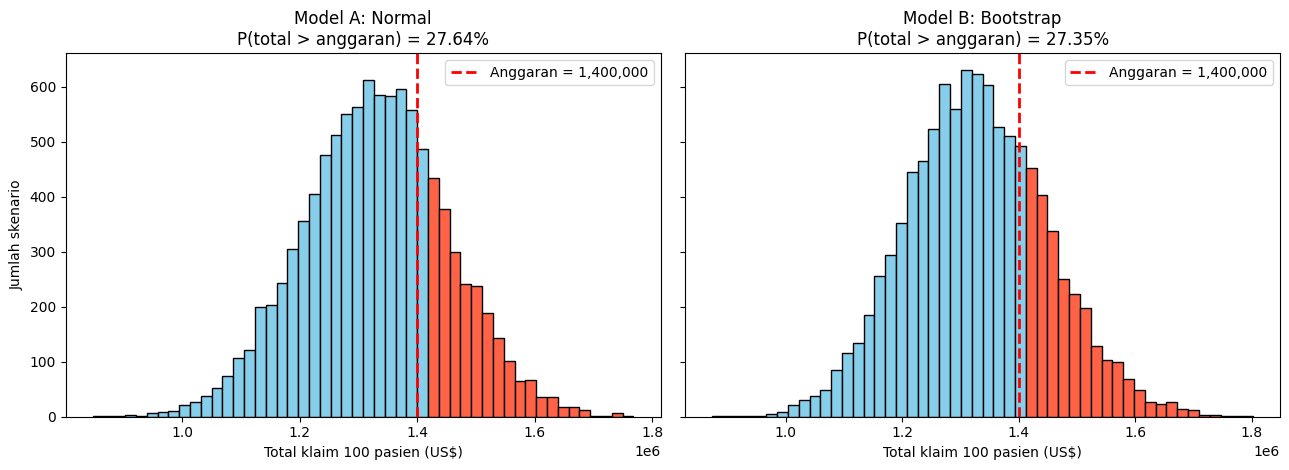

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, total, nama in zip(axes, [total_A, total_B], ["Model A: Normal", "Model B: Bootstrap"]):
    p = (total > ANGGARAN).mean()
    n, bins, patches = ax.hist(total, bins=50, edgecolor="black", color="skyblue")
    for b, patch in zip(bins[:-1], patches):
        if b >= ANGGARAN:
            patch.set_facecolor("tomato")            # area risiko
    ax.axvline(ANGGARAN, color="red", lw=2, ls="--", label=f"Anggaran = {ANGGARAN:,.0f}")
    ax.set_title(f"{nama}\nP(total > anggaran) = {p:.2%}")
    ax.set_xlabel("Total klaim 100 pasien (US$)"); ax.legend()
axes[0].set_ylabel("Jumlah skenario")
plt.tight_layout()
plt.savefig("histogram_hasil_simulasi.png", dpi=130)
plt.show()

### 3.3 Sensitivitas terhadap Besar Anggaran

In [11]:
anggaran_uji = [1_300_000, 1_350_000, 1_400_000, 1_450_000, 1_500_000, 1_600_000]
tabel = pd.DataFrame({
    "Anggaran (US$)": anggaran_uji,
    "P(lebih) Model A": [(total_A > a).mean() for a in anggaran_uji],
    "P(lebih) Model B": [(total_B > a).mean() for a in anggaran_uji],
})
print(tabel.round(4).to_string(index=False))

v95 = np.percentile(total_B, 95)
print(f"\nAnggaran agar peluang kelebihan hanya 5% (Model B): {v95:,.0f} "
      f"({v95 / (N_PASIEN * mu) - 1:+.1%} dari ekspektasi)")

 Anggaran (US$)  P(lebih) Model A  P(lebih) Model B
        1300000            0.5945            0.5845
        1350000            0.4340            0.4187
        1400000            0.2764            0.2735
        1450000            0.1587            0.1558
        1500000            0.0819            0.0824
        1600000            0.0136            0.0158

Anggaran agar peluang kelebihan hanya 5% (Model B): 1,532,191 (+15.4% dari ekspektasi)


### 3.4 Konvergensi: Berapa Iterasi yang Cukup?

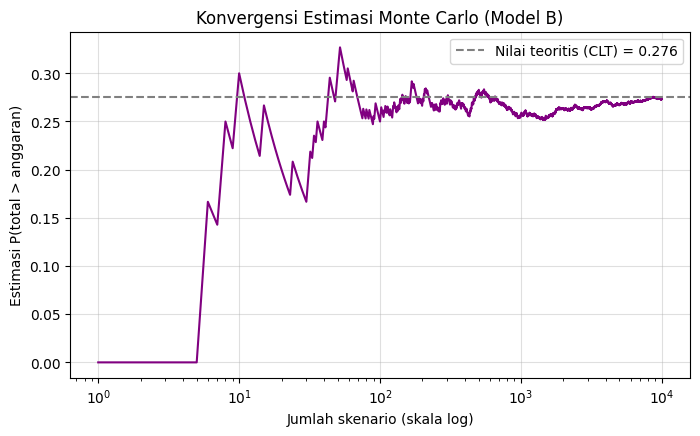

Estimasi dengan    100 skenario: 0.2500
Estimasi dengan  1,000 skenario: 0.2570
Estimasi dengan  5,000 skenario: 0.2672
Estimasi dengan 10,000 skenario: 0.2735


In [12]:
indikator = (total_B > ANGGARAN).astype(float)
p_kumulatif = np.cumsum(indikator) / np.arange(1, N_SIM + 1)

plt.figure(figsize=(8, 4.5))
plt.plot(np.arange(1, N_SIM + 1), p_kumulatif, color="purple")
plt.axhline(p_clt, color="gray", ls="--", label=f"Nilai teoritis (CLT) = {p_clt:.3f}")
plt.xscale("log")
plt.xlabel("Jumlah skenario (skala log)"); plt.ylabel("Estimasi P(total > anggaran)")
plt.title("Konvergensi Estimasi Monte Carlo (Model B)"); plt.legend(); plt.grid(alpha=0.4)
plt.savefig("konvergensi.png", dpi=130)
plt.show()
for n in (100, 1_000, 5_000, 10_000):
    print(f"Estimasi dengan {n:>6,} skenario: {p_kumulatif[n - 1]:.4f}")

### 3.5 Skenario Tambahan: Jika Porsi Perokok Lebih Tinggi
Pasien baru belum tentu memiliki komposisi yang sama dengan data historis (sekitar 20% perokok). Simulasi berikut mengubah porsi perokok di antara 100 pasien baru.

In [13]:
klaim_perokok = df.loc[df["smoker"] == "yes", "charges"].to_numpy()
klaim_bukan = df.loc[df["smoker"] == "no", "charges"].to_numpy()
porsi_data = (df["smoker"] == "yes").mean()

baris = []
for porsi in [porsi_data, 0.30, 0.40]:
    np.random.seed(NIM)
    perokok = np.random.rand(N_SIM, N_PASIEN) < porsi
    klaim = np.where(perokok,
                     np.random.choice(klaim_perokok, size=(N_SIM, N_PASIEN)),
                     np.random.choice(klaim_bukan, size=(N_SIM, N_PASIEN)))
    total = klaim.sum(axis=1)
    baris.append({"Porsi perokok": f"{porsi:.1%}", "Rata-rata total": total.mean(), "P(total > anggaran)": (total > ANGGARAN).mean()})
print(pd.DataFrame(baris).round(4).to_string(index=False))

Porsi perokok  Rata-rata total  P(total > anggaran)
        20.5%   1,328,586.7191               0.2748
        30.0%   1,552,772.3754               0.8739
        40.0%   1,788,965.4467               0.9967


## Analisis Hasil dan Kesimpulan

**Jawaban pertanyaan bisnis.** Dengan anggaran US$ 1.400.000 untuk 100 pasien baru, probabilitas total klaim melebihi anggaran adalah sekitar **27,4%** (Model B bootstrap), dan 27,6% pada Model A (Normal), sama dengan nilai teoritis berdasarkan Central Limit Theorem (27,6%). Artinya sekitar satu dari empat skenario mengalami kelebihan klaim. Anggaran yang hanya 5,4% di atas ekspektasi total klaim (US$ 1.327.912) belum memberi ruang aman yang memadai.

**Dua model memberi hasil hampir sama.** Distribusi satu klaim tidak normal: condong ke kanan (skewness 1,5) dan 13,6% tarikan dari Normal(μ, σ) bernilai negatif, yang tidak realistis. Namun total dari 100 klaim cenderung berdistribusi Normal (Central Limit Theorem), sehingga Model A dan Model B menghasilkan probabilitas yang hampir sama. Model B lebih dapat dipercaya karena tidak menghasilkan klaim negatif, dan lebih tepat bila yang dianalisis adalah klaim per pasien atau kelompok kecil.

**Besar anggaran yang aman.** Agar peluang kelebihan hanya 5%, anggaran perlu sekitar US$ 1.532.000 (15,4% di atas ekspektasi), dan untuk peluang 1% sekitar US$ 1.627.000. Tabel sensitivitas menunjukkan peluang kelebihan turun cepat dari 59% (anggaran US$ 1,3 juta) menjadi 1,6% (US$ 1,6 juta).

**Konvergensi.** Estimasi probabilitas dengan 100 skenario adalah 25,0%, dengan 1.000 skenario 25,7%, dengan 5.000 skenario 26,7%, dan dengan 10.000 skenario 27,4%. Semakin banyak skenario, estimasi semakin stabil dan mendekati nilai teoritis, sesuai Hukum Bilangan Besar. Galat acak estimasi pada 10.000 skenario sekitar 0,45 poin persentase.

**Sensitivitas komposisi pasien.** Rata-rata klaim perokok (US$ 32.050) jauh di atas bukan perokok (US$ 8.441). Jika porsi perokok di antara pasien baru naik dari 20,5% menjadi 30%, probabilitas kelebihan anggaran melonjak menjadi 87,4%, dan pada 40% menjadi 99,7%. Jadi komposisi risiko pasien lebih menentukan daripada fluktuasi acak; perusahaan sebaiknya menyesuaikan anggaran atau premi dengan komposisi pasien yang diharapkan.

**Keterbatasan.**
1. Pasien baru diasumsikan memiliki karakteristik yang sama dengan 1.337 pasien dalam data, dan klaim antar pasien diasumsikan saling bebas.
2. Anggaran US$ 1.400.000 adalah asumsi; angka sesungguhnya dari perusahaan dapat mengubah probabilitas secara besar.
3. Data berasal dari satu sumber contoh (dalam dolar AS), sehingga belum tentu mewakili portofolio asuransi tertentu.
4. Simulasi tidak memodelkan inflasi biaya kesehatan, klaim katastropik di luar rentang data (maksimum US$ 63.770), atau perubahan komposisi pasien dari waktu ke waktu.

**Kesimpulan.** Simulasi Monte Carlo berbasis data historis berhasil mengubah data klaim menjadi estimasi risiko yang bisa dibaca bisnis: dengan anggaran US$ 1,4 juta untuk 100 pasien, peluang kelebihan klaim sekitar 27%. Hasilnya konsisten antara model Normal, bootstrap, dan teori, dan memberi dasar untuk menetapkan anggaran yang lebih aman (sekitar US$ 1,53 juta untuk risiko 5%) serta menilai dampak komposisi perokok.


## Referensi
- Kaggle. *Medical Cost Personal Datasets* (miri choi). https://www.kaggle.com/datasets/mirichoi0218/insurance
- Weisstein, E. W. *Monte Carlo Method*. MathWorld. https://mathworld.wolfram.com/MonteCarloMethod.html
- Raychaudhuri, S. (2008). Introduction to Monte Carlo simulation. *2008 Winter Simulation Conference*.